# $Q$-learning on linear quadratic problem
In this notebook, we run the $Q$-learning algorithm on a linear quadratic (LQ) control problem. 

## Summary of the algorithm
Here, we consider minimizing the average cost, so we will have no discounting factor and we consider the differential cost in our Bellman equation.
Since the dynamical system is linear and the value function is quadratic, we consider a quadratic $Q$ function as follows

\begin{align*}
Q(s,a) =\begin{bmatrix}
s^{T} & a^{T}
\end{bmatrix}\begin{bmatrix}
g_{ss} & g_{sa}\\
g_{sa}^{T} & g_{aa} \end{bmatrix}\begin{bmatrix}
s\\a \end{bmatrix}= z^{T} G z
\end{align*}
where $z=\begin{bmatrix}
s^{T} & a^{T}
\end{bmatrix}^{T} $ and $G= \begin{bmatrix}
g_{ss} & g_{sa}\\
g_{sa}^{T} & g_{aa} \end{bmatrix}$.

The policy is given by 

\begin{align*}
\pi = -g_{aa}^{-1}g_{sa}^{T} \: s = K s
\end{align*}

We start right away by selecting a stabilizing policy (or equivalently initializing the $Q$-function such that the resulting policy is stabilizing). Selecting a stabilizing policy is crucial for convergence of Least Square Temporal Difference (LSTD) algorithms. In each iteration of the algorithm, we do the following

* i. We rollout the environment using the current policy to compute the average cost.
* ii. We rollout the environment to collect data for $Q$ learning by following these steps:
    * ii.a. We initialize empty histories for `states=[]`, `actions=[]`, `costs=[]`, `next_states=[]`.
    * ii.b. We observe the `state` $s$ and select the `action` $a$ according to
    
    `a = K @ state + stddev * np.random.randn(n_a).`
    
    * ii.c. We derive the environment using $a$ and observe the `cost` $c$ and the next state $s^{\prime}$.
    * ii.d. We add $s,\:a,\:c,\:s^{\prime}$ to the history batch `states`, `actions`, `costs`, `next_states`.
    * ii.e. We continue from ii.b. until the episode ends.
* iii. We estimate the quadratic kernel of the $Q$ function. Let $vecv(v)=[v_1^2,\: 2v_1 v_2,...,2v_1 v_n,\:v_2^2,...,\: 2v_2 v_n,\: ... ,v_n^2]^{T}$. The LSTD estimation of $G$ is given by

\begin{align*}		
vecs(G)= ( \frac{1}{T}\sum_{t=1}^{T} \Psi_t (\Psi_t- \Psi_{t+1})^{T} )^{-1} ( \frac{1}{T}\sum_{t=1}^{T} \Psi_t (c_t - \lambda) ), 
\end{align*}

where $\Psi_t=vecv(z_t)$, $z_t = [s_t^{T},\:a_t^{T}]^{T}$ and $T$ is the rollout length.

* iv. We update the policy by
\begin{align*}
\pi = -g_{aa}^{-1}g_{sa}^{T} \: s = K \: s.
\end{align*}


## Importing libraries
This notebook is self-contained and only needs `numpy`, `scipy` and `matplotlib`.

In [1]:
import numpy as np
import scipy.linalg as LA
from scipy import odr
import matplotlib.pyplot as plt

## Helper code
The cells below define everything the experiment needs:
* `LinK`: a linear policy $a = Ks$, with optional Gaussian exploration noise.
* `inst_variable`, `vecv`, `SquareMat`, `GtoP`: the instrumental-variable estimator and the quadratic-feature helpers used by LSTD.
* `Linear_Quadratic`: the stochastic LQ environment $s_{t+1} = A s_t + B a_t + w_t$ with $w_t \sim \mathcal{N}(0, \epsilon^2 I)$ and stage cost $s^T Q s + a^T R a$, plus analytical tools such as the LQR gain, stability check and infinite-horizon cost.
* `MODEL`: the model-building (certainty-equivalence) approach. It estimates $(A, B)$ from data and solves the Riccati equation.
* `Storing_Mat` / `Storing_Mat_opt`: containers for the results.
* `PLTLIB`: the plotting utilities.

In [2]:
class LinK:
    '''Linear policy a = K s (rows of s are states), optionally with Gaussian exploration.'''
    def __init__(self, K):
        self.K = K
        self.m, self.n = self.K.shape
        self.stddev = 0.0

    def lin_policy(self, x):
        '''x: [T, n] -> actions [T, m]'''
        return x @ self.K.T

    def make_sampling_on(self, stddev):
        self.stddev = stddev

    def sample_lin_policy(self, x):
        '''Sample a ~ N(K x, stddev^2 I)'''
        return x @ self.K.T + self.stddev * np.random.randn(len(x), self.m)


def inst_variable(x, y, z):
    '''Instrumental-variable estimate of theta in y = x theta + noise, with instrument z. x, z: [T, n], y: [T].'''
    T, n = x.shape
    lhs = z.T @ x / T
    rhs = (z.T @ y / T).reshape((n, 1))
    return LA.inv(lhs + 1e-5 * np.eye(n)) @ rhs


def vecv(x):
    '''Quadratic features of the rows of x: [x1^2, 2x1x2, ..., 2x1xn, x2^2, ..., xn^2]. [T, n] -> [T, n(n+1)/2]'''
    n = x.shape[1]
    i, j = np.triu_indices(n)
    return np.where(i == j, 1.0, 2.0) * x[:, i] * x[:, j]


def SquareMat(v, n):
    '''Inverse of vecv: symmetric n x n matrix from its upper-triangular entries (row by row).'''
    P = np.zeros((n, n))
    P[np.triu_indices(n)] = np.ravel(v)
    return P + np.triu(P, 1).T


def GtoP(G, K):
    '''Value-function kernel P = [I K'] G [I K']' associated with the Q-function kernel G and the gain K.'''
    n = K.shape[1]
    M = np.concatenate((np.eye(n), K.T), axis=1)
    return M @ G @ M.T

In [3]:
class Linear_Quadratic:
    '''Stochastic LQ system s+ = A s + B a + ep*w, stage cost s'Qs + a'Ra. States are row vectors.'''
    def __init__(self, A, B, Q, R, x0, ep):
        self.A = A.astype('float32')
        self.B = B.astype('float32')
        self.Q = Q.astype('float32')
        self.R = R.astype('float32')
        self.n, self.m = B.shape
        self.ep = ep
        self.Qn = ep**2 * np.eye(self.n)  # process-noise covariance
        self.x0 = x0.astype('float32')
        self.x = self.x0
        self.P_opt, self.K_opt = self.lqr_gain(self.Q, self.R)

    def resetx(self):
        self.x = self.x0

    def step(self, a):
        c = (self.x @ self.Q @ self.x.T + a @ self.R @ a.T).item()
        self.x = self.x @ self.A.T + a @ self.B.T + self.ep * np.random.randn(1, self.n)
        return self.x, c

    def one_rollout(self, policy, T):
        '''Roll out `policy` for T steps from x0. Returns states, actions, costs, next_states.'''
        states = np.zeros((T, self.n), dtype='float32')
        actions = np.zeros((T, self.m), dtype='float32')
        costs = np.zeros(T, dtype='float32')
        next_states = np.zeros((T, self.n), dtype='float32')
        self.resetx()
        for t in range(T):
            states[t, :] = self.x
            actions[t, :] = policy(self.x)
            next_states[t, :], costs[t] = self.step(actions[t, :])
        return states, actions, costs, next_states

    def lqr_gain(self, given_q, given_r):
        '''Solve the discrete ARE. Returns (P, K) with a = K s.'''
        try:
            P = LA.solve_discrete_are(self.A, self.B, given_q, given_r)
            K = -LA.inv(self.B.T @ P @ self.B + given_r) @ self.B.T @ P @ self.A
        except (LA.LinAlgError, ValueError):
            P = np.zeros((self.n, self.n))
            K = np.zeros((self.m, self.n))
        return P, K

    def a_cl(self, K):
        return self.A + self.B @ K

    def is_stable(self, K):
        return np.amax(np.abs(LA.eigvals(self.a_cl(K)))) < (1.0 - 1.0e-6)

    def P_and_Pe_associated_to_K(self, K):
        '''Value-function kernel P of u = K x and its normalized distance from P_opt (100 I and inf if unstable).'''
        if not self.is_stable(K):
            return 100.0 * np.eye(self.n), float("inf")
        P = LA.solve_discrete_lyapunov(self.a_cl(K).T, self.Q + K.T @ self.R @ K)
        return P, LA.norm(P - self.P_opt, 2) / LA.norm(self.P_opt, 2)

    def dist_from_optimal_K(self, K):
        '''Normalized spectral-norm distance ||K - K_opt|| / ||K_opt|| (inf if unstable).'''
        if not self.is_stable(K):
            return float("inf")
        return LA.norm(K - self.K_opt, 2) / LA.norm(self.K_opt, 2)

    def cost_inf_K(self, K):
        '''Infinite-horizon average cost tr(P_K Qn) of u = K x (inf if unstable).'''
        if not self.is_stable(K):
            return float("inf")
        P, _ = self.P_and_Pe_associated_to_K(K)
        return np.trace(P @ self.Qn)

    def cost_finite_average_K(self, K, T):
        '''Empirical average cost of one rollout of the deterministic policy u = K x over T steps (1000 if unstable).'''
        if not self.is_stable(K):
            return 1000.0
        _, _, cost, _ = self.one_rollout(LinK(K).lin_policy, T)
        return np.sum(cost) / T


class MODEL:
    '''Model building: estimate (A, B) from data by orthogonal distance regression, then solve the Riccati equation.'''
    def __init__(self, sysdyn: Linear_Quadratic):
        self.dyn = sysdyn
        self.n, self.m = self.dyn.B.shape

    def nominal_AB(self, K, N, T, explore_mag=10, res_time=100):
        '''
        Estimate A and B from N rollouts of length T with the exploring policy a = K s + explore_mag * noise.
        Rollouts longer than res_time are split into shorter ones (reset to x0) for numerical stability.
        '''
        Lin_gain = LinK(K)
        Lin_gain.make_sampling_on(explore_mag)
        if T >= res_time:
            N = int(np.ceil(N * T / res_time))
            T = res_time

        states_batch = np.zeros((self.n, N, T))
        next_states_batch = np.zeros((self.n, N, T))
        actions_batch = np.zeros((self.m, N, T))
        for k in range(N):
            states, actions, _, next_states = self.dyn.one_rollout(Lin_gain.sample_lin_policy, T)
            states_batch[:, k, :] = states.T
            actions_batch[:, k, :] = actions.T
            next_states_batch[:, k, :] = next_states.T

        regressors = np.vstack((states_batch.reshape(self.n, N * T), actions_batch.reshape(self.m, N * T)))
        A_nom = np.zeros((self.n, self.n))
        B_nom = np.zeros((self.n, self.m))
        for i in range(self.n):
            data = odr.RealData(x=regressors, y=next_states_batch[i, :, :].reshape(1, N * T))
            beta = odr.ODR(data, odr.Model(lambda p, x: p @ x), beta0=np.zeros(self.n + self.m)).run().beta
            A_nom[i, :] = beta[:self.n]
            B_nom[i, :] = beta[self.n:]
        return A_nom, B_nom

    def nominal_PK(self, K0, N, T, explore_mag=10, res_time=100):
        '''
        Iterative model building: in each of the N iterations, roll out the current gain, estimate (A, B),
        and replace the gain by the LQR gain of the estimated model. Returns P, K.
        '''
        K = K0
        for _ in range(N):
            if not self.dyn.is_stable(K):
                return self.unstable_P_and_K()
            A_nom, B_nom = self.nominal_AB(K, 1, T, explore_mag=explore_mag, res_time=res_time)
            try:
                P = LA.solve_discrete_are(A_nom, B_nom, self.dyn.Q, self.dyn.R)
                K = -LA.inv(B_nom.T @ P @ B_nom + self.dyn.R) @ B_nom.T @ P @ A_nom
            except (LA.LinAlgError, ValueError):
                P, K = self.unstable_P_and_K()
        return P, K

    def unstable_P_and_K(self):
        return np.zeros((self.n, self.n)), np.zeros((self.m, self.n))

In [4]:
class Storing_Mat:
    '''Results of a learning method per (MC trial, checkpoint). Column 0 is the initial gain K0.'''
    def __init__(self, name, sysdyn, K0, n_mc, n_points, T):
        self.name = name
        self.J_inf = np.zeros((n_mc, n_points))
        self.J_fin = np.zeros((n_mc, n_points))
        self.K = np.zeros([sysdyn.m, sysdyn.n, n_mc, n_points])
        self.Ke = np.zeros([n_mc, n_points])
        self.P = np.zeros([sysdyn.n, sysdyn.n, n_mc, n_points])
        self.Pe = np.zeros([n_mc, n_points])
        for trial in range(n_mc):
            self.K[:, :, trial, 0] = K0
            self.J_fin[trial, 0] = sysdyn.cost_finite_average_K(K0, T)
            self.J_inf[trial, 0] = sysdyn.cost_inf_K(K0)
            self.Ke[trial, 0] = sysdyn.dist_from_optimal_K(K0)


class Storing_Mat_opt:
    '''Reference values for the optimal LQR gain.'''
    def __init__(self, name, sysdyn, n_mc, n_points, T):
        self.name = name
        self.P = sysdyn.P_opt
        self.K = sysdyn.K_opt
        self.J_inf = sysdyn.cost_inf_K(self.K)
        self.J_fin = np.zeros((n_mc, n_points))
        for trial in range(n_mc):
            self.J_fin[trial, 0] = sysdyn.cost_finite_average_K(self.K, T)


class PLTLIB:
    '''Plots of median (and interquartile range) performance vs. rollout length.'''
    def __init__(self, j_inf_opt):
        self._colors = ['#2D328F', '#F15C19', '#BF3EFF', '#81b13c']
        self._marker = ['o', '3', '^', '>']
        self._linestyle = ['dashdot', 'dashed', (0, (3, 5, 1, 5, 1, 5)), 'dotted']
        self._j_inf_opt = j_inf_opt

    def _style(self, i):
        return dict(linestyle=self._linestyle[i], marker=self._marker[i], color=self._colors[i],
                    linewidth=3, markersize=10)

    def _finish(self, ax, xlab, ylab):
        ax.set_xlabel(xlab, fontsize=14)
        ax.set_ylabel(ylab, fontsize=14)
        ax.tick_params(labelsize=14)
        ax.legend(fontsize=13)
        ax.grid(True)
        ax.figure.set_size_inches(9, 6)
        plt.show()

    def frac_stable(self, j, tot_samples, mc_trials, alg, xlab):
        fig, ax = plt.subplots()
        for i in range(len(alg)):
            ax.plot(tot_samples, 1 - np.sum(np.isinf(j[i]), axis=0) / mc_trials, label=alg[i], **self._style(i))
        ax.axis([tot_samples[0], tot_samples[-1], 0, 1.2])
        self._finish(ax, xlab, 'Fraction stable')

    def est_e(self, e, tot_samples, alg, xlab, ylab, uplim):
        fig, ax = plt.subplots()
        for i in range(len(alg)):
            ax.plot(tot_samples, np.median(e[i], axis=0), label=alg[i], **self._style(i))
        ax.axis([tot_samples[0], tot_samples[-1], 0, uplim])
        self._finish(ax, xlab, ylab)

    def relative_inf_cost(self, j, tot_samples, alg, xlab, uplim=6):
        fig, ax = plt.subplots()
        for i in range(len(alg)):
            rel = (j[i] - self._j_inf_opt) / self._j_inf_opt
            ax.plot(tot_samples, np.median(rel, axis=0), label=alg[i], **self._style(i))
            ax.fill_between(tot_samples, np.percentile(rel, 25, axis=0), np.percentile(rel, 75, axis=0),
                            alpha=0.25, color=self._colors[i])
        ax.axis([tot_samples[0], tot_samples[-1], 0, uplim])
        self._finish(ax, xlab, 'Relative average cost error')

## Making the environment
We select the random seed and make the linear quadratic problem. We also initialize the controller gain `K0`.


In [5]:
rand_seed = 1
np.random.seed(rand_seed)
A = np.array([[1.0, 1.0], [0.0, 1.0]])
B = np.array([[0.0], [1.0]])
x0 = np.array([[-1.0, 0.0]], dtype='float32')
ep = 0.1
Q = np.array([[1, 0], [0, 1]])
R = np.array([[1]])

Mysys = Linear_Quadratic(A, B, Q, R, x0, ep)
_, K0 = Mysys.lqr_gain(200*Mysys.Q, Mysys.R)

## Making the $Q$-learning agent
We define the $Q$-learning class here.

In [6]:
class Q_learning:
    def __init__(self, sysdyn:Linear_Quadratic):
        # self.rand_seed = 1
        # np.random.seed(self.rand_seed)
        self.dyn = sysdyn
        self.n, self.m = self.dyn.B.shape
        self.n_phi = int((self.n + self.m) * (self.n + self.m + 1) / 2)
        self.P = np.zeros((self.n, self.n))

    def ql(self, K0, N, T, explore_mag=1.0):
        '''
        Q learning loop to iterate over policy iteration and policy improvement
        :param K0: The initial policy gain
        :param N: Number of iterations
        :param T: Trajectory length
        :param explore_mag: The amount of randomness in Q learning
        :return: The kernel of the value function P and the controller gain K
        '''
        self.K = K0
        for k in range(N):

            # If the controller is stable, do an iteration
            if self.dyn.is_stable(self.K):

                # Policy evaluaion
                G = self.q_evaluation(T, explore_mag)

                # Policy improvement
                self.K = self.q_improvement(G)
                P = GtoP(G, self.K)

            # If the controller is not stable, return some unstable values for P and K
            else:
                P, self.K = self.unstable_P_and_K()

        return P, self.K

    def q_evaluation(self, T, explore_mag):
        # creating the linear policy and turning sampling on
        Lin_gain = LinK(self.K)
        Lin_gain.make_sampling_on(explore_mag)

        # Do one rollout to compute the average cost
        _, _, r, _ = self.dyn.one_rollout(Lin_gain.lin_policy, T)
        Lam = np.sum(r)/T

        # Do one rollout to save data for Q learning
        states, actions, costs, next_states = self.dyn.one_rollout(Lin_gain.sample_lin_policy, T)

        # Making the state z and the next state z
        z = np.concatenate((states, actions), axis=1)
        next_z = np.concatenate((next_states, Lin_gain.lin_policy(next_states)), axis=1)

        # estimating the Q parameter using instrumental variable
        x_iv = vecv(z) - vecv(next_z)
        y_iv = costs - Lam
        z_iv = vecv(z)
        q_vec = inst_variable(x_iv, y_iv, z_iv)
        return SquareMat(q_vec, self.n+self.m)

    def q_improvement(self, G):
        return - LA.inv(G[self.dyn.n:, self.dyn.n:]) @ G[self.dyn.n:, 0:self.dyn.n]

    def unstable_P_and_K(self):
        return np.zeros((self.n, self.n)), np.zeros((self.m, self.n))


We have built the $Q$-learning class. It remains to build an object from this class. You can change the following hyper parameters if you like

* `T`: The trajectory or rollout length. You can make it shorter or longer to see if you can get a better result.
* `n_iteration`: Total number of iterations. You can increase it to see if you can get a better result.
* `n_monte_carlo`: We run $Q$-learning (which contains `n_iteration`) on the LQ problem for `n_monte_carlo` times to analyze the performance.
* `explore_mag`: The amount of exploration in $Q$-learning. For example, you can set `explore_mag=0` while recalling ql function from Q_learning class below and verify that you cannot get any stable controller.

It would be interesting to compare the performance of the $Q$-learning algorithm with a model-building approach. In a model-building approach, we estimate $(A, B)$ by using the collected data and solve the model-based Algebraic Riccati Equation assuming that the estimated matrices are the true matrices. We have built the model-learning class and below, we build an object of this class.

Try different trajectory lengths and number of iterations to see the effect of them.

In [7]:
My_q_learning = Q_learning(Mysys)
My_model_learning = MODEL(Mysys)
T = np.array([0, 20, 50, 80, 100])
n_iteration = 5
n_monte_carlo = 10

We initialize some matrices to store the results of the algorithms for different numbers of iterations and monte carlo evaluation.

In [8]:
OPT = Storing_Mat_opt("Optimal Solution", Mysys, n_monte_carlo, len(T), T[-1])
Q = Storing_Mat("Q-learning", Mysys, K0, n_monte_carlo, len(T), T[-1])
MODEL_LEARNING = Storing_Mat("Model-learning", Mysys, K0, n_monte_carlo, len(T), T[-1])
Methods = [Q, MODEL_LEARNING]

## Start learning
Now, we evaluate the performance of $Q$-learning on the LQ problem. The algorithm is run for the trajectory length given in the `T` array. We also repeat the simulation for `n_monte_carlo` times and report the mean value for the parameters and errors to reduce the effect of randomness on our learning. In practice, you need to use a larger `n_monte_carlo ` than 10. We have chosen 10 to get the results fast. The $Q$-learning algorithm returns the estimated gain $\bar{K}$. In the second loop below, we compute the finite average cost, infinite average cost, and the error from the exact $K_{opt}$.


In [9]:
for t in range(1, len(T)):
    for trial in range(n_monte_carlo):
        print('Rollout Length: %d, MC trial: %d' % (T[t], trial))

        print('Q learning')
        Q.P[:, :, trial, t], Q.K[:, :, trial, t] = My_q_learning.ql(K0, n_iteration, T[t], explore_mag=1.0)

        print('Model learning')
        MODEL_LEARNING.P[:, :, trial, t], MODEL_LEARNING.K[:, :, trial, t] = \
            My_model_learning.nominal_PK(K0, n_iteration, T[t])

for t in range(1, len(T)):
    for trial in range(n_monte_carlo):
        OPT.J_fin[trial, t] = Mysys.cost_finite_average_K(OPT.K, T[t])
        for meth in Methods:
            meth.J_inf[trial, t] = Mysys.cost_inf_K(meth.K[:, :, trial, t])
            meth.J_fin[trial, t] = Mysys.cost_finite_average_K(meth.K[:, :, trial, t], T[t])
            meth.Ke[trial, t] = Mysys.dist_from_optimal_K(meth.K[:, :, trial, t])
            _, meth.Pe[trial, t] = Mysys.P_and_Pe_associated_to_K(meth.K[:, :, trial, t])


Rollout Length: 20, MC trial: 0
Q learning
Model learning
Rollout Length: 20, MC trial: 1
Q learning
Model learning
Rollout Length: 20, MC trial: 2
Q learning
Model learning
Rollout Length: 20, MC trial: 3
Q learning
Model learning
Rollout Length: 20, MC trial: 4
Q learning
Model learning
Rollout Length: 20, MC trial: 5
Q learning
Model learning
Rollout Length: 20, MC trial: 6
Q learning
Model learning
Rollout Length: 20, MC trial: 7
Q learning
Model learning
Rollout Length: 20, MC trial: 8
Q learning
Model learning
Rollout Length: 20, MC trial: 9
Q learning
Model learning
Rollout Length: 50, MC trial: 0
Q learning
Model learning
Rollout Length: 50, MC trial: 1
Q learning
Model learning
Rollout Length: 50, MC trial: 2
Q learning
Model learning
Rollout Length: 50, MC trial: 3
Q learning
Model learning
Rollout Length: 50, MC trial: 4
Q learning
Model learning
Rollout Length: 50, MC trial: 5
Q learning
Model learning
Rollout Length: 50, MC trial: 6
Q learning
Model learning
Rollout Length

## Results
We plot the result of the simulation here. The first figure shows the fraction of times the algorithm returns stable policies in all iterations. The second figure shows the error between the estimated gain and the optimal gain; $K_e =\frac{||\bar{K}-K_{opt}||}{||K_{opt}||}$. The third figure shows the error between the infinite average costs by the estimated controller gain and the optimal controller $K_e =\frac{||\bar{J}-J_{opt}||}{||J_{opt}||}$. In all three figures, the zero rollout length refers to the initiation of the algorithm. 

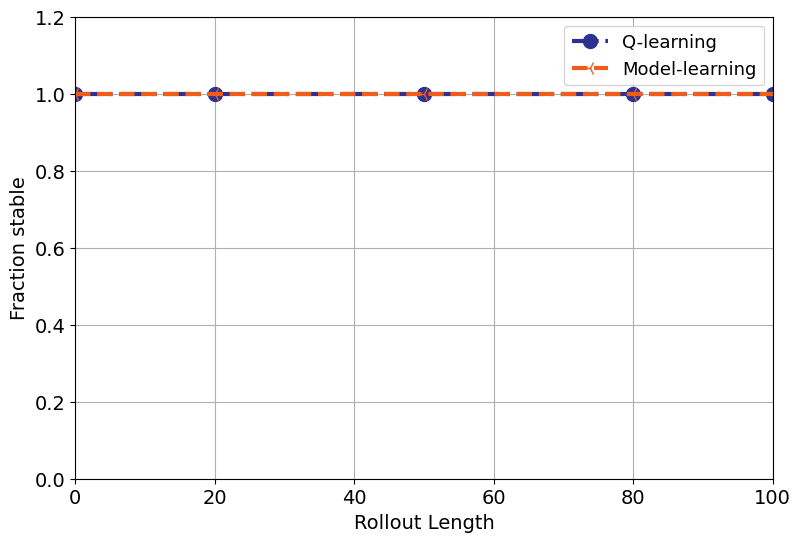

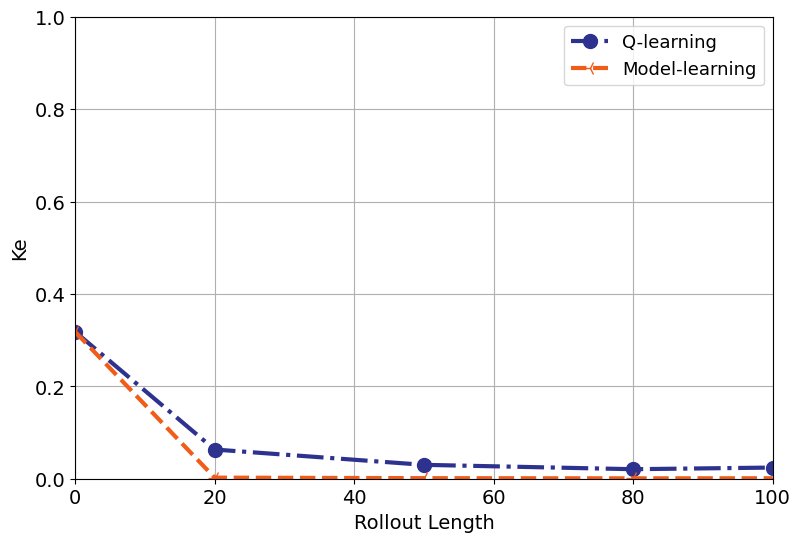

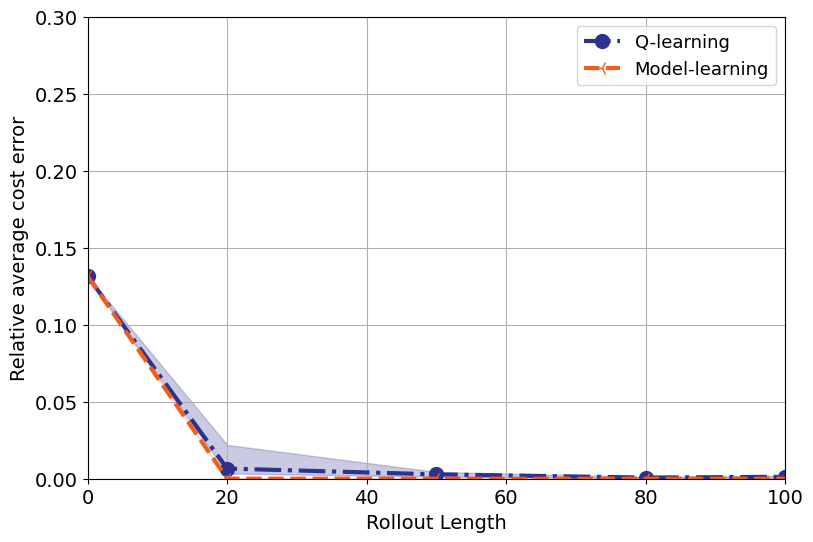

In [10]:
MyPlot = PLTLIB(OPT.J_inf)
J = [meth.J_inf for meth in Methods]
Lab = [meth.name for meth in Methods]
MyPlot.frac_stable(J, T, n_monte_carlo, Lab, 'Rollout Length')
MyPlot.est_e([meth.Ke for meth in Methods], T, Lab, 'Rollout Length', "Ke", 1)
MyPlot.relative_inf_cost(J, T, Lab, 'Rollout Length', uplim=0.3)

We print the estimated controller gain with the $Q$-learning and the model-building approach, and compare it with the analytical optimal solution. As you can see, they are pretty close.

In [11]:
print('\nThe optimal k \n', OPT.K)
for meth in Methods:
    print('\nMean of estimated K using', meth.name, '\n', np.mean(meth.K[:, :, :, -1], axis=2))

for meth in Methods:
    print('\nMedian of Ke using', meth.name, np.median(meth.Ke[:, -1]))


The optimal k 
 [[-0.42208244 -1.24392885]]

Mean of estimated K using Q-learning 
 [[-0.42240745 -1.24659223]]

Mean of estimated K using Model-learning 
 [[-0.42249052 -1.24494002]]

Median of Ke using Q-learning 0.02414419613313578

Median of Ke using Model-learning 0.0010156174793155659


The median of $K_e$ will be around $1\%$. [It has been shown that as the trajectory length encreases, the estimated controller gain converges to the optimal controller.](http://proceedings.mlr.press/v99/tu19a/tu19a.pdf) Moreover, observe that even the simplest model-learning approach performs super good!